In [3]:
!mamba install pandas

/bin/bash: line 1: mamba: command not found


In [ ]:
datafile["extra"].hist()
plt.show()

In [4]:
import pandas as pd
datafile=pd.read_csv ("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/sleep.csv")
datafile.groupby('group').describe()

A                                                extra        ...  \
      count  mean      std   min    25%   50%    75%   max count  mean  ...   
group                                                                   ...   
1      10.0   5.5  3.02765   1.0   3.25   5.5   7.75  10.0  10.0  0.75  ...   
2      10.0  15.5  3.02765  11.0  13.25  15.5  17.75  20.0  10.0  2.33  ...   

                    ID                                            
        75%  max count mean      std  min   25%  50%   75%   max  
group                                                             
1      1.70  3.7  10.0  5.5  3.02765  1.0  3.25  5.5  7.75  10.0  
2      4.15  5.5  10.0  5.5  3.02765  1.0  3.25  5.5  7.75  10.0  

[2 rows x 24 columns]

<Axes: ylabel='Density'>

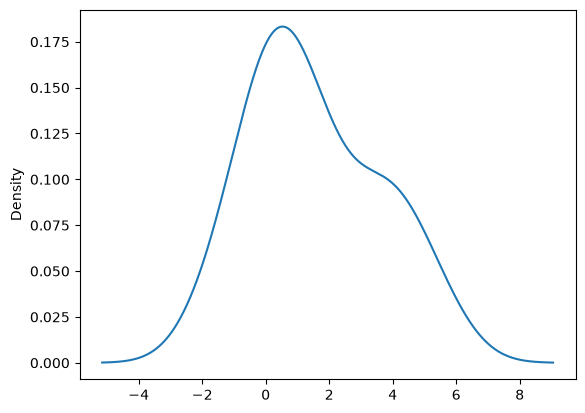

In [ ]:
# Density curve
datafile["extra"].plot(kind="density")
figure 1

In [5]:
source=pd.read_csv ("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/Income2023.csv")

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

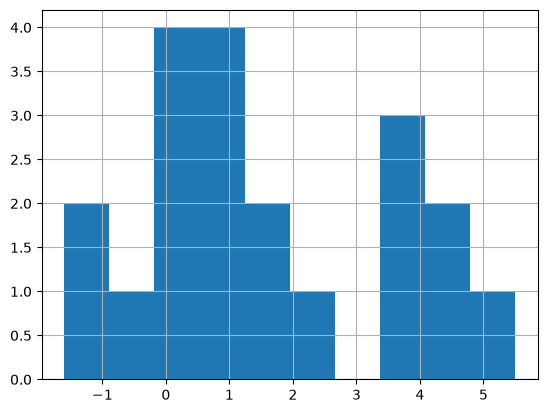

In [ ]:
datafile["extra"].hist()
plt.show()
Figure 2

<Axes: >

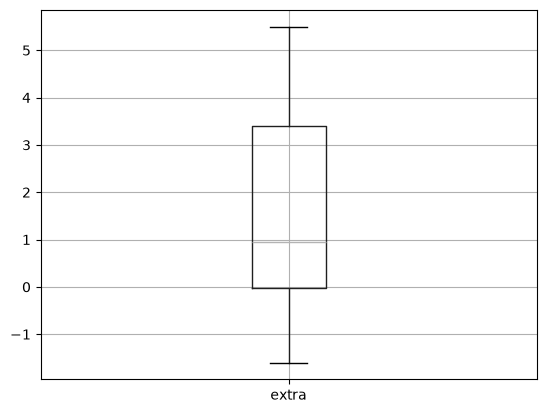

In [ ]:
datafile.boxplot(column="extra")
Figure 3

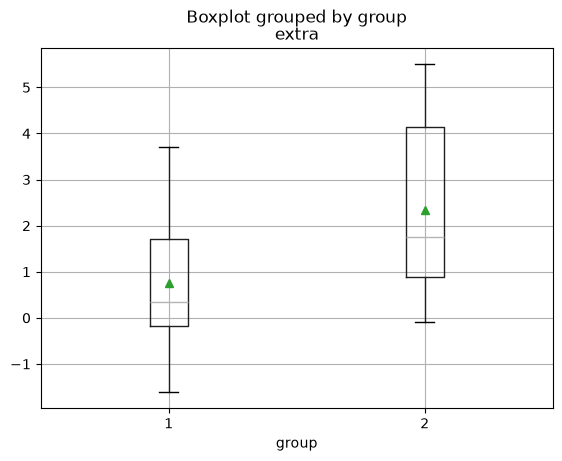

In [ ]:
datafile.boxplot(column="extra", by="group", showmeans=True)
plt.show()
Figure 4

<Axes: >

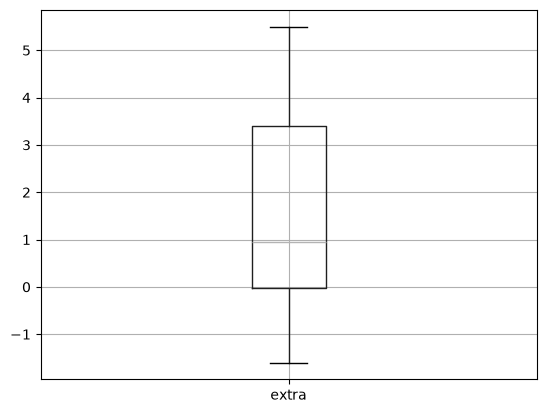

In [ ]:
datafile.boxplot(column="extra")
2 A (1)

<Axes: >

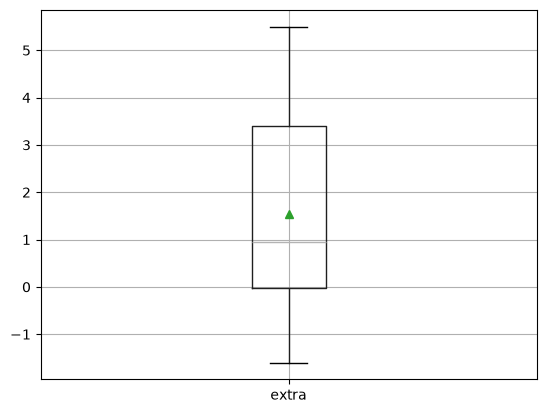

In [ ]:
datafile.boxplot(column="extra", showmeans=True)
2 A (2)

<Axes: ylabel='Density'>

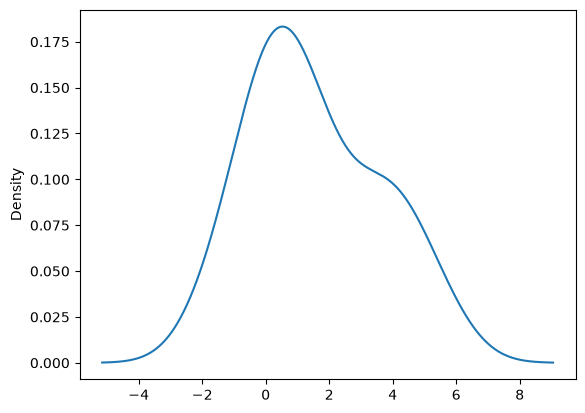

In [ ]:
datafile["extra"].plot(kind="density")
2 B (1)

group
1    Axes(0.125,0.11;0.775x0.77)
2    Axes(0.125,0.11;0.775x0.77)
Name: extra, dtype: object

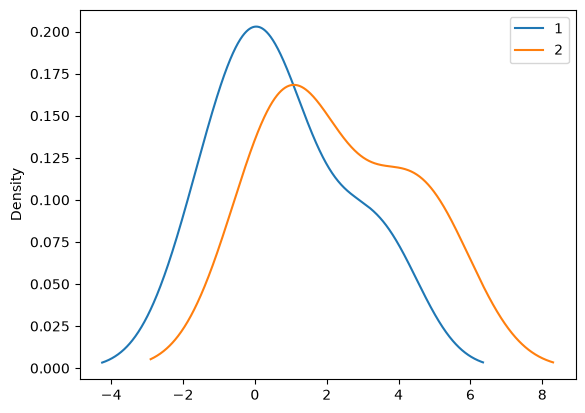

In [ ]:
datafile.groupby("group")["extra"].plot(kind="density", legend=True)
2 B (2)

In [ ]:
datafile.groupby('group').describe()
2 C (1)

A                                                extra        ...  \
      count  mean      std   min    25%   50%    75%   max count  mean  ...   
group                                                                   ...   
1      10.0   5.5  3.02765   1.0   3.25   5.5   7.75  10.0  10.0  0.75  ...   
2      10.0  15.5  3.02765  11.0  13.25  15.5  17.75  20.0  10.0  2.33  ...   

                    ID                                            
        75%  max count mean      std  min   25%  50%   75%   max  
group                                                             
1      1.70  3.7  10.0  5.5  3.02765  1.0  3.25  5.5  7.75  10.0  
2      4.15  5.5  10.0  5.5  3.02765  1.0  3.25  5.5  7.75  10.0  

[2 rows x 24 columns]

In [ ]:
datafile.groupby('group')['extra'].describe()
2 C (2)

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
1,10.0,0.75,1.789010,-1.6,-0.175,0.35,1.70,3.7
2,10.0,2.33,2.002249,-0.1,0.875,1.75,4.15,5.5


<Axes: >

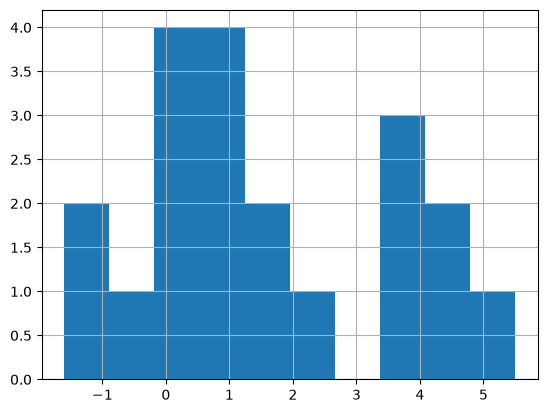

In [ ]:
datafile["extra"].hist() #this is a comment!
2 D (1)

<Axes: >

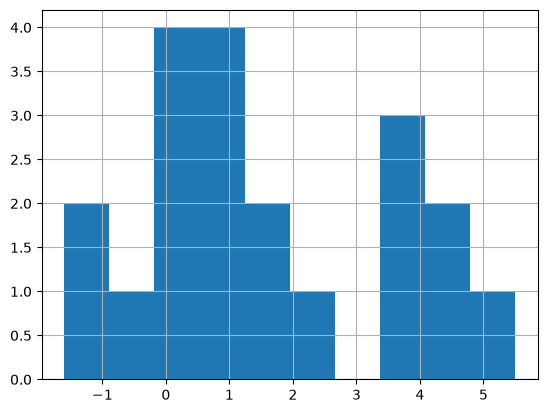

In [ ]:
datafile["extra"].hist()
2 D (2)

In [ ]:
datafile.groupby("group")["extra"].agg(["count", "mean", "std", "skew"])
3 (1)

,count,mean,std,skew
group,,,,
1,10,0.75,1.789010,0.580921
2,10,2.33,2.002249,0.385806


/tmp/ipykernel_1742/1682085294.py:3: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


<Axes: >

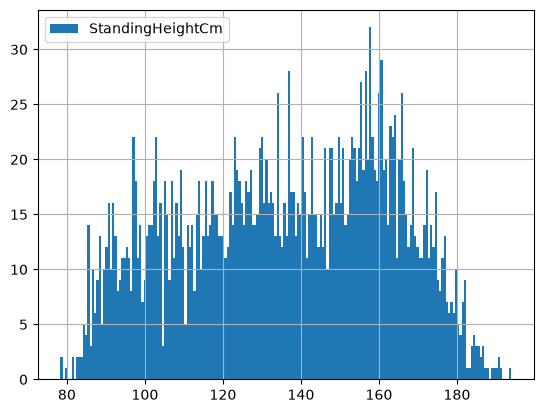

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")

children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]
children["StandingHeightCm"].hist(bins=200, legend=True)

/tmp/ipykernel_1742/1642320611.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)


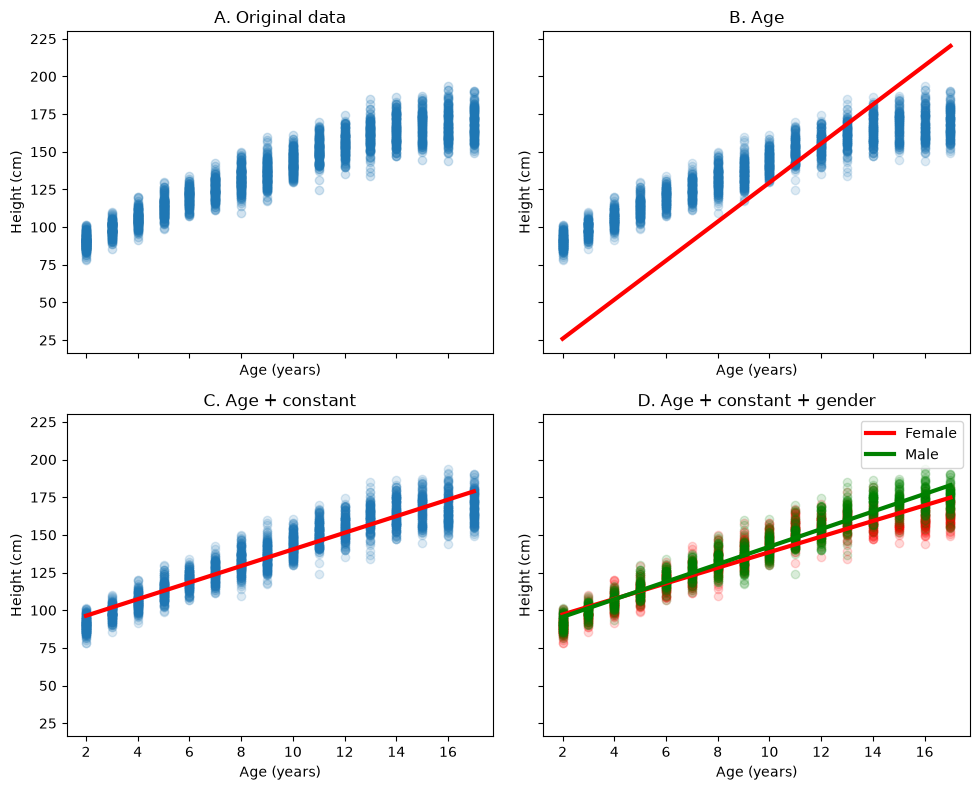

In [2]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children  = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna()

m_age = LinearRegression(fit_intercept=False).fit(children[["AgeInYearsAtScreening"]],children["StandingHeightCm"])
m_age_const = LinearRegression().fit(children[["AgeInYearsAtScreening"]], children["StandingHeightCm"])

m_full = LinearRegression().fit(children[["AgeInYearsAtScreening", "Gender_code"]],children["StandingHeightCm"])
children = children.sort_values("AgeInYearsAtScreening")

children["pred_age"] = m_age.predict(children[["AgeInYearsAtScreening"]])
children["pred_age_const"] = m_age_const.predict(children[["AgeInYearsAtScreening"]])
children["pred_full"] = m_full.predict(children[["AgeInYearsAtScreening", "Gender_code"]])

children["Age_Gender"] = (children["AgeInYearsAtScreening"] * children["Gender_code"])

m_interaction = LinearRegression().fit(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]],children["StandingHeightCm"])

children["pred_interaction"] = m_interaction.predict(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]])
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# A: Original data
ax[0,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.2)
ax[0,0].set_title("A. Original data")

# B: Age only
ax[0,1].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[0,1].plot(children["AgeInYearsAtScreening"], children["pred_age"], color="red", lw=3)
ax[0,1].set_title("B. Age")
# C: Age + constant
ax[1,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[1,0].plot(children["AgeInYearsAtScreening"], children["pred_age_const"], color="red", lw=3)
ax[1,0].set_title("C. Age + constant")

# D: Age + constant + gender
for g, color, label in [(0, "red", "Female"),(1, "green", "Male")]:
    tmp = children[children["Gender_code"] == g].sort_values("AgeInYearsAtScreening")
    ax[1,1].scatter(tmp["AgeInYearsAtScreening"],tmp["StandingHeightCm"],alpha=.15,color=color)
    ax[1,1].plot(tmp["AgeInYearsAtScreening"],tmp["pred_interaction"],color=color,lw=3,label=label)
ax[1,1].legend()
ax[1,1].set_title("D. Age + constant + gender")

for a in ax.ravel():
    a.set_xlabel("Age (years)")
    a.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()